# Quantum Chemistry Part 2

NicDeclic  
2026-10-14

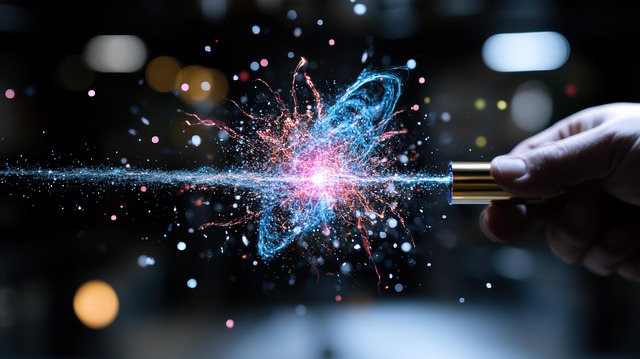

> *“Your only adversary is the mirror that refuses to reflect all your
> colors.”*  
> — **Professor Alvin**

------------------------------------------------------------------------

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nicdeclic/quantum-molecular-computing/blob/main/posts/quantum-chemistry/index.ipynb)

In [1]:
import sys
if 'google.colab' in sys.modules:
    # 1. Download qmc.py from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/qmc.py
    
    # 2. Download requirements.txt from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/requirements.txt

    # 3. Install dependencies
    !pip install -q -r requirements.txt

sys.path.insert(0, "../../src") # Select root directory
from qmc import * # QMC library

%reload_ext autoreload
%autoreload 2

------------------------------------------------------------------------

Closed Form Molecules

``` python
# Create a conjugated carbon molecule
mol1 = CarbonMolecule("Double Honeycomb")

# Add atoms
c1_1 = mol1.add_atom(x=-0.25, y=1)
c1_2 = mol1.add_atom(x=0.25, y=1)
c1_3 = mol1.add_atom(x=-0.5, y=0.5)
c1_4 = mol1.add_atom(x=0.5, y=0.5)
c1_5 = mol1.add_atom(x=-0.25, y=0)
c1_6 = mol1.add_atom(x=0.25, y=0)
c1_7 = mol1.add_atom(x=-0.5, y=-0.5)
c1_8 = mol1.add_atom(x=0.5, y=-0.5)
c1_9 = mol1.add_atom(x=-0.25, y=-1)
c1_10 = mol1.add_atom(x=0.25, y=-1)

# Add bonds
b1_1 = mol1.add_bond(c1_1, c1_2, order="single", label="A", role="input")
b1_2 = mol1.add_bond(c1_2, c1_4, order="single")
b1_3 = mol1.add_bond(c1_1, c1_3, order="single")
b1_4 = mol1.add_bond(c1_3, c1_5, order="single")
b1_5 = mol1.add_bond(c1_4, c1_6, order="single")
b1_6 = mol1.add_bond(c1_5, c1_6, order="single")
b1_7 = mol1.add_bond(c1_5, c1_7, order="single")
b1_8 = mol1.add_bond(c1_6, c1_8, order="single")
b1_9 = mol1.add_bond(c1_7, c1_9, order="single")
b1_10 = mol1.add_bond(c1_8, c1_10, order="single")
b1_11 = mol1.add_bond(c1_9, c1_10, order="single", label="B", role="output")

# Draw with Schemdraw
# mol1.draw()

all_resonances = mol1.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw() 
```

<table style="width:100%;">
<colgroup>
<col style="width: 33%" />
<col style="width: 33%" />
<col style="width: 33%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="33.3%"
data-layout-align="center">
<p>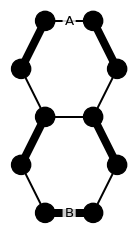</p>
</div></td>
<td style="text-align: center;"><div width="33.3%"
data-layout-align="center">
<p>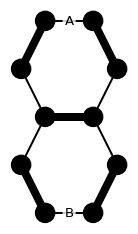</p>
</div></td>
<td style="text-align: center;"><div width="33.3%"
data-layout-align="center">
<p>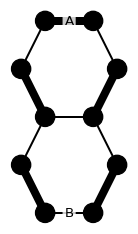</p>
</div></td>
</tr>
</tbody>
</table>

``` python
CarbonMolecule.resonance_table(all_resonances)
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$\begin{array}{|c|c|} \hline \mathbf{A}
&amp; \mathbf{B} \\ \hline 0 &amp; 1 \\ 0 &amp; 0 \\ 1 &amp; 0 \\ \hline
\end{array}$$</span></p>
</div></td>
</tr>
</tbody>
</table>

Classical boolean logic provides no native vocabulary to express such
non-uniform states.

Deterministic certainty dissolves here. We are forced to broaden our
theoretical horizons into statistics.

------------------------------------------------------------------------

## Probabilistic Bits (p-bits)

Probabilistic bits provide a robust mathematical framework for encoding
and processing information. By applying this formalism to carbon-carbon
bonds, we can natively capture the stochastic nature of chemical systems
and open up new frontiers in molecular computing.

Think of a coin toss. Once flipped, the coin can land on tails (state
**“0”**) or heads (state **“1”**).

With a fair coin, there is an equal probability—a 50% chance—of landing
on state “0” and a 50% chance of landing on state “1”.

Mathematically, we formulate probabilistic bits using the same
transition matrices introduced earlier. The only operational difference
lies in the values of the matrix elements.

- **A fair coin:** :

In [4]:
display_inline("Fair", "=", random.to_katex(show_labels=True))

The first element quantifies the probability of observing a **“0”**; the
second element quantifies the probability of observing a **“1”**.

We could also bias the coin so that it carries a one-in-four chance
(25%) of landing on “0”, and a three-in-four chance (75%) of landing on
“1”.

- **A biased coin:** :

In [5]:
biased = TransitionMatrix([
    [0.25, 0.75]
])

display_inline("Biased", "=", biased.to_katex(show_labels=True))

The limiting boundary case occurs when there is a 0% chance of being in
one state and a 100% chance of being in the other. Under these
conditions, deterministic certainty is recovered, and the probabilistic
bit collapses back into a classical boolean bit.

Any continuous probability distribution is physically admissible,
provided that two fundamental axioms are satisfied:  
1. Every individual element must lie strictly within the closed interval
$[0, 1]$.  
2. The elements along each row must sum to exactly **1** (equivalent to
100%—the total probability space). Consequently, there is no probability
leak into unmodeled states (for example, ruling out the pathological
edge case where the coin lands balanced on its side).

And because of the missing row values we must add a third axiom:

1.  The elements along a row representing an invalid state must sum to
    exactly **0** (dead-end).

------------------------------------------------------------------------

``` python
doubleHoneycomb = TransitionMatrix.from_resonances(all_resonances)

display_inline("DoubleHoneycomb", "=", doubleHoneycomb.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ DoubleHoneycomb =  \begin{array}{r|cc|}
\text{} &amp; \text{``0''} &amp; \text{``1''} \\  \hline \text{``0''}
&amp; 0.5 &amp; 0.5 \\ \text{``1''} &amp; 1 &amp; 0 \\  \hline
\end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

------------------------------------------------------------------------

## Decomposition of a Molecule in Matrix Form

------------------------------------------------------------------------

## The Breakthrough

- NOR gate.

------------------------------------------------------------------------

## Double Connections

------------------------------------------------------------------------

## Cascading Parasitic Resonance (Molecular Epilepsy)

When a junction allows two unauthorized boundary states to infiltrate
its truth table, these spurious modes do not remain localized. They
infect adjacent nodes, triggering what we might call Cascading Parasitic
Resonance — or, in more intuitive neuro-computational terms, a form of
molecular epilepsy sweeping across the quantum network.

------------------------------------------------------------------------

## Couplers

------------------------------------------------------------------------

## Reverse Computing

- The choice of what bond is an input or an output is completely left to
  the observer. Molecules do not inherently have inputs and outputs.

- Transpose operation.

- The resonance states must be bijective.

------------------------------------------------------------------------

## 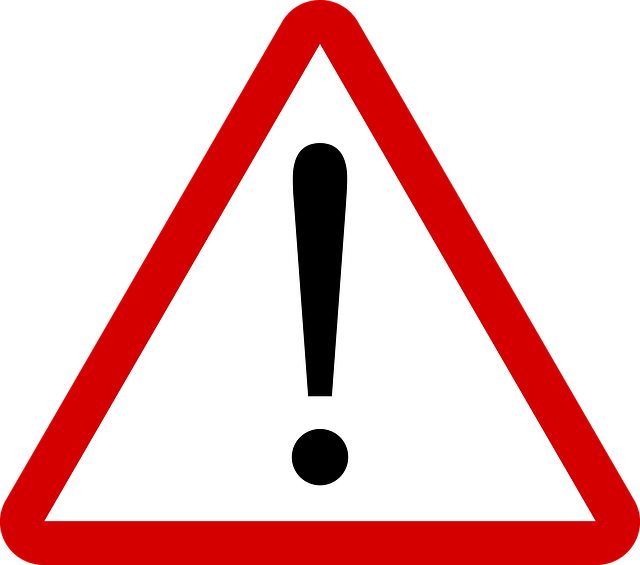 Speculations & Wild Thoughts

- If biological neural networks rely on aromatic π-electron resonance
  networks within synaptic receptors for ultrafast signaling, what
  happens when a molecular coupler suffers a geometric defect?  
  Could an epileptic seizure be the macroscopic manifestation of a
  microscopic state - leakage cascade — where the breakdown of a single
  quantum molecular parity check forces millions of synapses into a
  runaway, hypersynchronous parasitic resonance?

- The lyrics and vocal samples of the song “Set Theory” by Carbon Based
  Lifeforms “There are no answers. Only choices” were inspired by the
  2002 sci-fi film Solaris.

------------------------------------------------------------------------

👉 **Next chapter :**  
**[“The Emergence of Protobits”](../../posts/protobits/index.html)**